<a href="https://colab.research.google.com/github/dptel22/Nosh-Robotics/blob/main/Task_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!unzip -q "/content/egg.v3i.folder.zip" -d /content/
!unzip -q "/content/task1_outputs.zip" -d /content/task1_outputs

In [2]:
import json, time, cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image
from scipy import ndimage as ndi

DATA = Path("/content/egg.v3i.folder")
SAM  = Path("/content/task1_outputs/sam_masks")
out  = Path("/content/out"); out.mkdir(exist_ok=True)

imgs = sorted(p for p in DATA.rglob("*") if p.suffix.lower() in {".jpg", ".jpeg", ".png"})
mask_files = {p.stem: p for p in SAM.rglob("*.png")}
mask_of = {p.stem: mask_files.get(p.stem) or mask_files.get(p.stem + "_mask") for p in imgs}
missing = [s for s, m in mask_of.items() if m is None]
print(len(imgs), "images |", len(mask_files), "mask files | images with NO mask:", len(missing), missing[:5])
assert not missing, "fix the mask names/paths before going on"

def show(items, cols=4):
    rows = (len(items) + cols - 1) // cols
    fig, ax = plt.subplots(rows, cols, figsize=(4 * cols, 4 * rows), squeeze=False); ax = ax.ravel()
    for a in ax: a.axis("off")
    for a, (t, im) in zip(ax, items): a.imshow(im); a.set_title(t, fontsize=8)
    plt.show()

160 images | 160 mask files | images with NO mask: 0 []


In [3]:
!pip install -q imagehash
import re, imagehash
from sklearn.model_selection import GroupShuffleSplit
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components

src = np.array([re.sub(r"\.rf\.[0-9a-f]+", "", p.name) for p in imgs])
H = np.array([imagehash.phash(Image.open(p)).hash.flatten() for p in imgs])
dist = (H[:, None] != H[None]).sum(-1)
print("clusters by pHash threshold:", {t: connected_components(csr_matrix((dist <= t) | (src[:, None] == src[None])), directed=False)[0] for t in (0, 4, 8, 10, 12, 16)})

THR = 10
n_groups, groups = connected_components(csr_matrix((dist <= THR) | (src[:, None] == src[None])), directed=False)
dev_i, eval_i = next(GroupShuffleSplit(1, test_size=0.2, random_state=42).split(imgs, groups=groups))
assert not set(groups[dev_i]) & set(groups[eval_i])
print(f"{n_groups} groups, largest {np.bincount(groups).max()}; dev {len(dev_i)} / eval {len(eval_i)}; closest dev-vs-eval pHash distance {dist[np.ix_(dev_i, eval_i)].min()}")
json.dump({"dev": [imgs[i].name for i in dev_i], "eval": [imgs[i].name for i in eval_i], "thr": THR, "seed": 42}, open(out / "split.json", "w"))

clusters by pHash threshold: {0: 160, 4: 159, 8: 157, 10: 156, 12: 156, 16: 144}
156 groups, largest 2; dev 127 / eval 33; closest dev-vs-eval pHash distance 16


In [4]:
EL = lambda k: cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k))
DEFAULTS = dict(denoise="gauss", mode="otsu_gray", s_max=65, v_min=150, l_min=140, ab_tol=22, skin=False,
                morph=False, k_open=5, k_close=15, select="largest", min_area=0.005, max_area=0.98, min_solid=0.9, refine=None,
                gc_margin=0.08, gc_iters=4)
best = {**DEFAULTS, **globals().get("best", {})}     # re-running this cell keeps the config you already chose

def solid(comp):
    c = max(cv2.findContours(comp, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)[0], key=cv2.contourArea)
    hull = cv2.contourArea(cv2.convexHull(c))
    return cv2.contourArea(c) / hull if hull else 0.0

def egg_score(comp):                            # how egg-like is this blob? convex * ellipse-like * central * big
    c = max(cv2.findContours(comp, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)[0], key=cv2.contourArea)
    area = cv2.contourArea(c); h, w = comp.shape
    if area < 1 or len(c) < 5: return 0.0
    (cx, cy), (MA, ma), _ = cv2.fitEllipse(c)
    ell = np.pi * MA * ma / 4
    fit = min(area, ell) / max(area, ell, 1)
    dist = np.hypot(cx - w / 2, cy - h / 2) / np.hypot(w / 2, h / 2)
    return solid(comp) * fit * (1 - 0.5 * dist) * np.sqrt(area / (h * w))

def grabcut(img, m, iters=3, ring=15):          # refine the boundary: sure-FG core, uncertain ring, sure-BG outside
    gc = np.full(m.shape, cv2.GC_BGD, np.uint8)
    gc[cv2.dilate(m, EL(2 * ring + 1)) > 0] = cv2.GC_PR_BGD
    gc[m > 0] = cv2.GC_PR_FGD
    gc[cv2.erode(m, EL(2 * ring + 1)) > 0] = cv2.GC_FGD
    cv2.grabCut(img, gc, None, np.zeros((1, 65)), np.zeros((1, 65)), iters, cv2.GC_INIT_WITH_MASK)
    return np.where((gc == cv2.GC_FGD) | (gc == cv2.GC_PR_FGD), 255, 0).astype(np.uint8)

def seg(bgr, c):
    img = cv2.GaussianBlur(bgr, (5, 5), 0) if c["denoise"] == "gauss" else \
          cv2.bilateralFilter(bgr, 9, 50, 50) if c["denoise"] == "bilateral" else bgr
    if c["mode"] == "otsu_gray":                                    # intensity only
        m = cv2.threshold(cv2.cvtColor(img, cv2.COLOR_BGR2GRAY), 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)[1]
    elif c["mode"] == "grabcut":                                    # no colour rule: assume the egg is big and roughly central
        h, w = img.shape[:2]; g = int(c["gc_margin"] * min(h, w)); gc = np.zeros((h, w), np.uint8)
        cv2.grabCut(img, gc, (g, g, w - 2 * g, h - 2 * g), np.zeros((1, 65)), np.zeros((1, 65)), c["gc_iters"], cv2.GC_INIT_WITH_RECT)
        m = np.where((gc == cv2.GC_FGD) | (gc == cv2.GC_PR_FGD), 255, 0).astype(np.uint8)
    else:                                                           # white egg = high V, low S (+ neutral a*,b* in LAB)
        m = cv2.inRange(cv2.cvtColor(img, cv2.COLOR_BGR2HSV), (0, 0, c["v_min"]), (180, c["s_max"], 255))
        if c["mode"] == "hsv_lab":
            lab = cv2.cvtColor(img, cv2.COLOR_BGR2LAB)
            m &= cv2.inRange(lab, (c["l_min"], 128 - c["ab_tol"], 128 - c["ab_tol"]), (255, 128 + c["ab_tol"], 128 + c["ab_tol"]))
    if c["skin"]:                                                   # classic YCrCb skin range
        m[cv2.inRange(cv2.cvtColor(img, cv2.COLOR_BGR2YCrCb), (0, 133, 77), (255, 173, 127)) > 0] = 0
    if c["morph"]:
        m = cv2.morphologyEx(cv2.morphologyEx(m, cv2.MORPH_OPEN, EL(c["k_open"])), cv2.MORPH_CLOSE, EL(c["k_close"]))
    m = (ndi.binary_fill_holes(m > 0) * 255).astype(np.uint8)
    n, lab_, st, _ = cv2.connectedComponentsWithStats(m)
    comps = [k for k in range(1, n) if c["min_area"] <= st[k, cv2.CC_STAT_AREA] / m.size <= c["max_area"]]
    if c["select"] == "largest":
        keep = [1 + int(st[1:, cv2.CC_STAT_AREA].argmax())] if n > 1 else []
    elif c["select"] == "score":                                    # the single most egg-like blob
        keep = [max(comps, key=lambda k: egg_score((lab_ == k).astype(np.uint8)))] if comps else []
    else:                                                           # "shape": every blob that is big enough and convex
        keep = [k for k in comps if solid((lab_ == k).astype(np.uint8)) >= c["min_solid"]]
    out_ = np.zeros_like(m)
    for k in keep:
        comp = (lab_ == k).astype(np.uint8)
        cnt = max(cv2.findContours(comp, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)[0], key=cv2.contourArea)
        hull = cv2.convexHull(cnt)
        if c["refine"] == "hull": cv2.fillPoly(out_, [hull], 255)
        elif c["refine"] == "ellipse" and len(hull) >= 5: cv2.ellipse(out_, cv2.fitEllipse(hull), 255, -1)
        else: out_[comp > 0] = 255
    return grabcut(img, out_) if c["refine"] == "grabcut" and out_.any() else out_

In [5]:
CACHE = {}
def get(i):
    if i not in CACHE:
        bgr, a = cv2.imread(str(imgs[i])), np.array(Image.open(mask_of[imgs[i].stem]))
        gt = (a if a.ndim == 2 else a.max(-1)) > 0                      # works for 0/255, label images and RGB masks
        assert gt.shape == bgr.shape[:2], f"mask and image sizes differ for {imgs[i].name}: {gt.shape} vs {bgr.shape[:2]}"
        CACHE[i] = (bgr, gt)
    return CACHE[i]

def evaluate(cfg, idx):
    rows = []
    for i in idx:
        bgr, gt = get(i); pred = seg(bgr, cfg) > 127
        inter, union = (pred & gt).sum(), (pred | gt).sum()
        rows.append(dict(image=imgs[i].stem, folder=imgs[i].parent.name, iou=inter / union if union else 1.0,
                         dice=2 * inter / (pred.sum() + gt.sum()) if union else 1.0,
                         prec=inter / pred.sum() if pred.sum() else float(not gt.any()),
                         rec=inter / gt.sum() if gt.sum() else float(not pred.any())))
    return pd.DataFrame(rows)

LOG = out / "experiments.csv"
def trial(name, change, why):
    cfg = {**best, **change}                       # exactly the change on top of the config you kept so far
    t0 = time.time(); r = evaluate(cfg, dev_i); ms = (time.time() - t0) / len(dev_i) * 1000
    row = dict(trial=name, change=str(change), why=why, cfg=json.dumps(cfg), dev_miou=round(r.iou.mean(), 4), dev_median=round(r.iou.median(), 4),
               dev_dice=round(r.dice.mean(), 4), dev_prec=round(r.prec.mean(), 4), dev_rec=round(r.rec.mean(), 4), ms_per_img=round(ms),
               worst5=";".join(r.nsmallest(5, "iou").image.str[:14]), decision="")     # <- fill 'decision' BY HAND with your reason
    df = pd.DataFrame([row])
    if LOG.exists(): df = pd.concat([pd.read_csv(LOG), df])
    df.to_csv(LOG, index=False)
    print(f"{name}: mIoU {row['dev_miou']} median {row['dev_median']} Dice {row['dev_dice']} P {row['dev_prec']} R {row['dev_rec']} {row['ms_per_img']}ms | worst {row['worst5']}")
    return cfg, r

def look(r, cfg, n=4):                             # evidence for your keep/discard reason: green=correct, red=extra, blue=missed
    items = []
    for s in r.nsmallest(n, "iou").image:
        i = next(k for k in dev_i if imgs[k].stem == s); bgr, gt = get(i); pred = seg(bgr, cfg) > 127
        ov = bgr[:, :, ::-1].copy()
        for mask, col in [(gt & pred, (0, 255, 0)), (pred & ~gt, (255, 0, 0)), (gt & ~pred, (0, 0, 255))]:
            ov[mask] = (ov[mask] * .4 + np.array(col) * .6).astype(np.uint8)
        items += [(s[:16], bgr[:, :, ::-1]), (f"IoU {r.set_index('image').iou[s]:.2f}", ov)]
    show(items)

def sweep(key, values):                            # pick from the PLATEAU of this curve, not the single best point
    s = pd.Series({v: evaluate({**best, key: v}, dev_i).iou.mean() for v in values})
    s.plot(marker="o", title=f"dev mIoU vs {key}"); plt.show(); return s

T0: mIoU 0.5334 median 0.5648 Dice 0.6382 P 0.646 R 0.7074 35ms | worst not_damaged_82;not_damaged_13;not_damaged_14;not_damaged_10;not_damaged_12


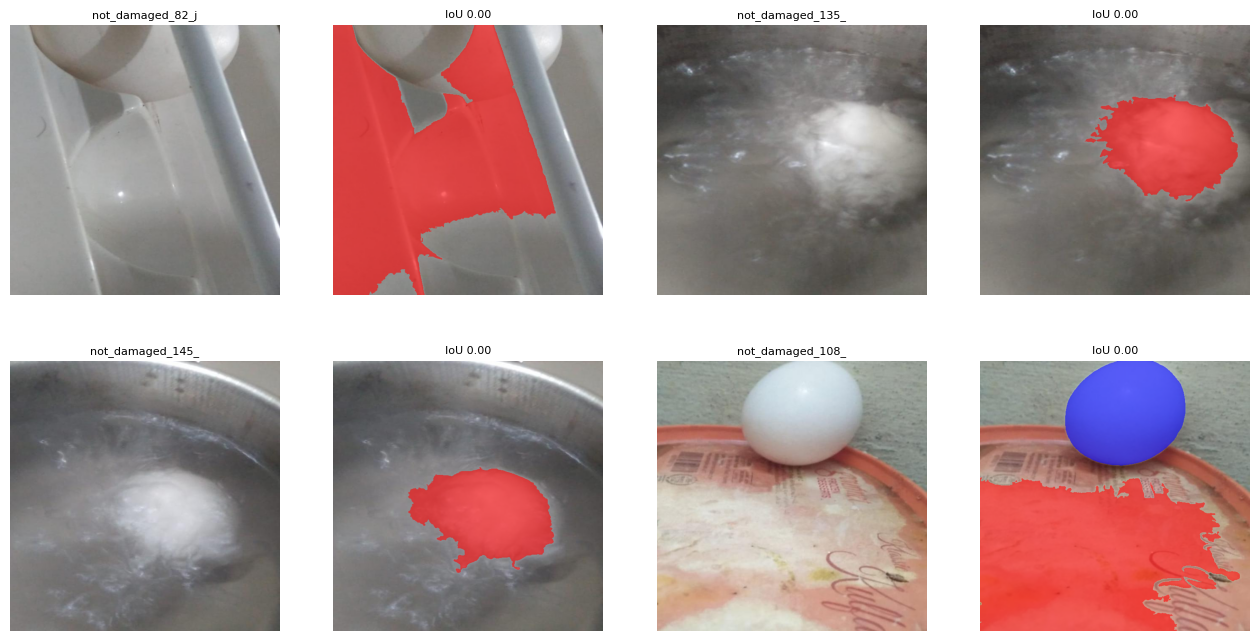

In [6]:
c, r = trial("T0", {}, "baseline: gray + Gaussian + Otsu + largest blob (zero tuning)")
look(r, c)

T1: mIoU 0.5377 median 0.5564 Dice 0.6439 P 0.6881 R 0.6937 28ms | worst not_damaged_82;not_damaged_13;not_damaged_14;not_damaged_10;not_damaged_12


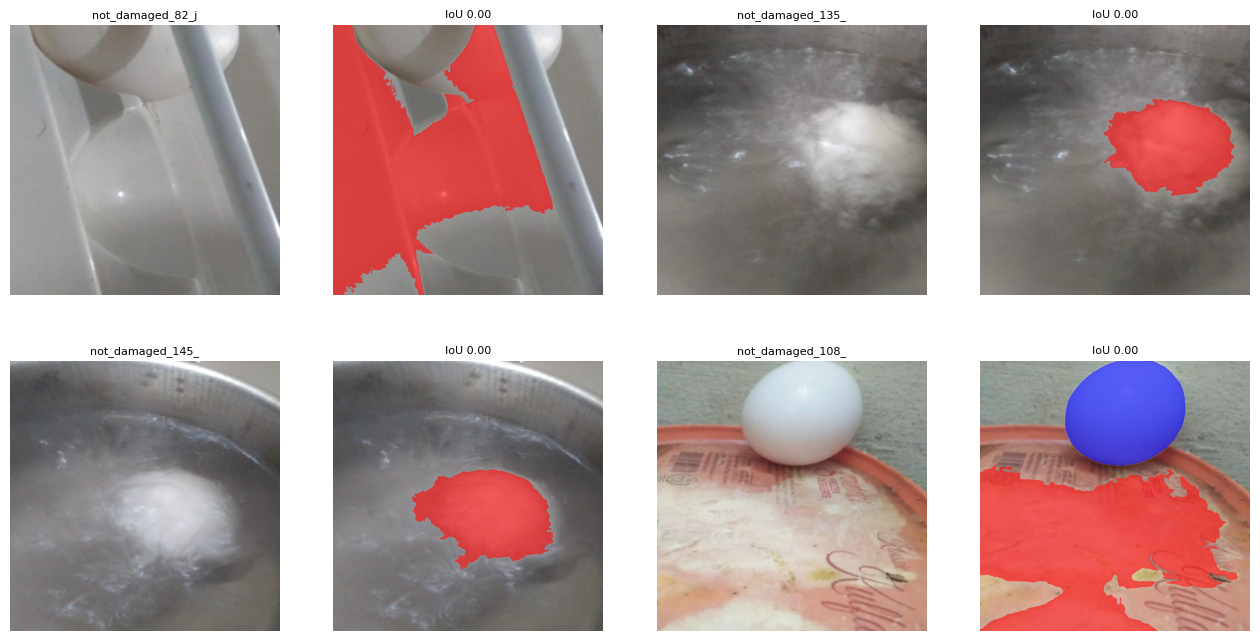

In [7]:
c, r = trial("T1", dict(mode="hsv"), "white egg = high V, LOW saturation; should reject warm skin and dark background")
look(r, c)

In [11]:
FINAL = dict(best); json.dump(FINAL, open(out / "final_config.json", "w"), indent=1)
(out / "pred_masks").mkdir(exist_ok=True)
for p in imgs: cv2.imwrite(str(out / "pred_masks" / f"{p.stem}.png"), seg(cv2.imread(str(p)), FINAL))
print("frozen:", FINAL)
!cp -r /content/out /content/egg_task2_out

frozen: {'denoise': 'gauss', 'mode': 'otsu_gray', 's_max': 65, 'v_min': 150, 'l_min': 140, 'ab_tol': 22, 'skin': False, 'morph': False, 'k_open': 5, 'k_close': 15, 'select': 'largest', 'min_area': 0.005, 'max_area': 0.98, 'min_solid': 0.9, 'refine': None}


4 near-duplicate pairs at THR = 10


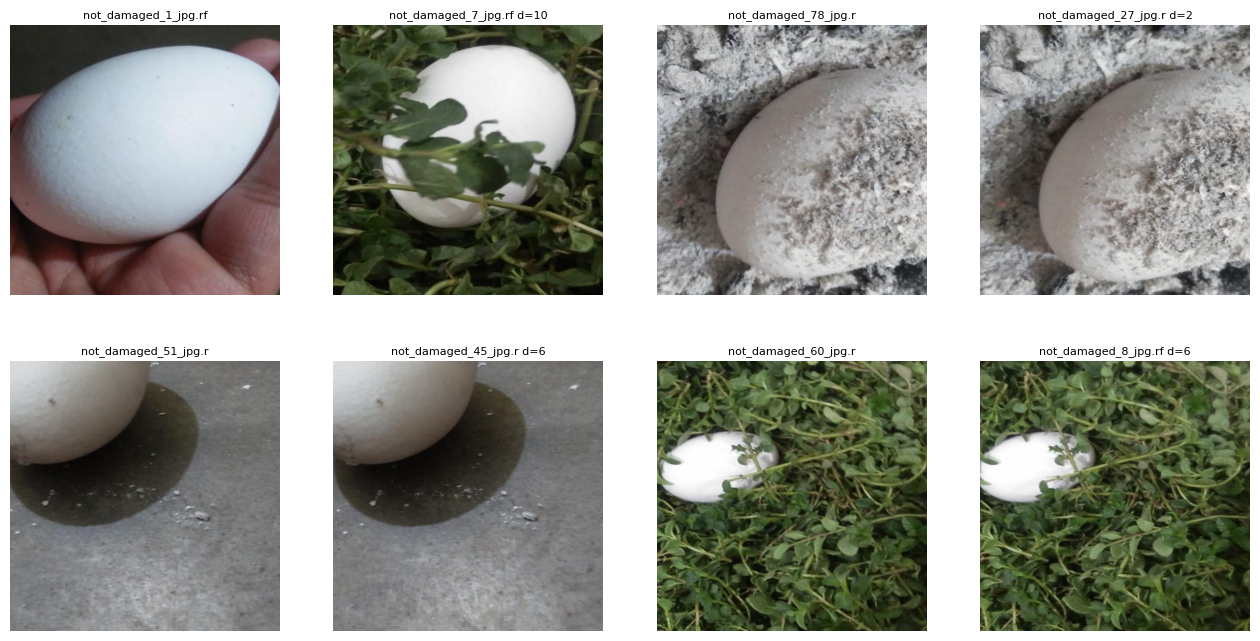

In [12]:
# Which images were merged by the duplicate check? (evidence for your threshold choice in the report)
pairs = [(i, j) for i in range(len(imgs)) for j in range(i + 1, len(imgs)) if dist[i, j] <= THR or src[i] == src[j]]
print(len(pairs), "near-duplicate pairs at THR =", THR)
show([item for i, j in pairs for item in [(f"{imgs[i].stem[:20]}", np.array(Image.open(imgs[i]).convert("RGB"))),
                                           (f"{imgs[j].stem[:20]} d={dist[i, j]}", np.array(Image.open(imgs[j]).convert("RGB")))]])

IoU by folder:
            count   mean
folder                 
Unlabeled      2  0.000
egg          125  0.546

IoU by name prefix:
              count   mean
image                    
not_damaged    127  0.538

correlation with IoU:
 iou          1.00
n_eggs_gt    0.34
gt_area      0.56
egg_S       -0.48
egg_V        0.57
bg_V        -0.30
Name: iou, dtype: float64

8 worst:
                                                   image  iou  n_eggs_gt  gt_area  egg_S  egg_V  bg_V
 not_damaged_82_jpg.rf.f905343e80e6b260a7742f28feb3c189  0.0          0     0.00    NaN    NaN 152.0
not_damaged_135_jpg.rf.02a086fe23ccf60011459bfb7caf2384  0.0          0     0.00    NaN    NaN 113.0
not_damaged_145_jpg.rf.25714bc97a0d9ac1853a29abed3e262a  0.0          0     0.00    NaN    NaN 118.0
not_damaged_108_jpg.rf.a33af29f3c7418568afac5dbc975a0da  0.0          1     0.14   24.0  207.0 194.0
not_damaged_124_jpg.rf.9617304acd90ed469d263561b3c37552  0.0          0     0.00    NaN    NaN 131.0
 not_damaged_

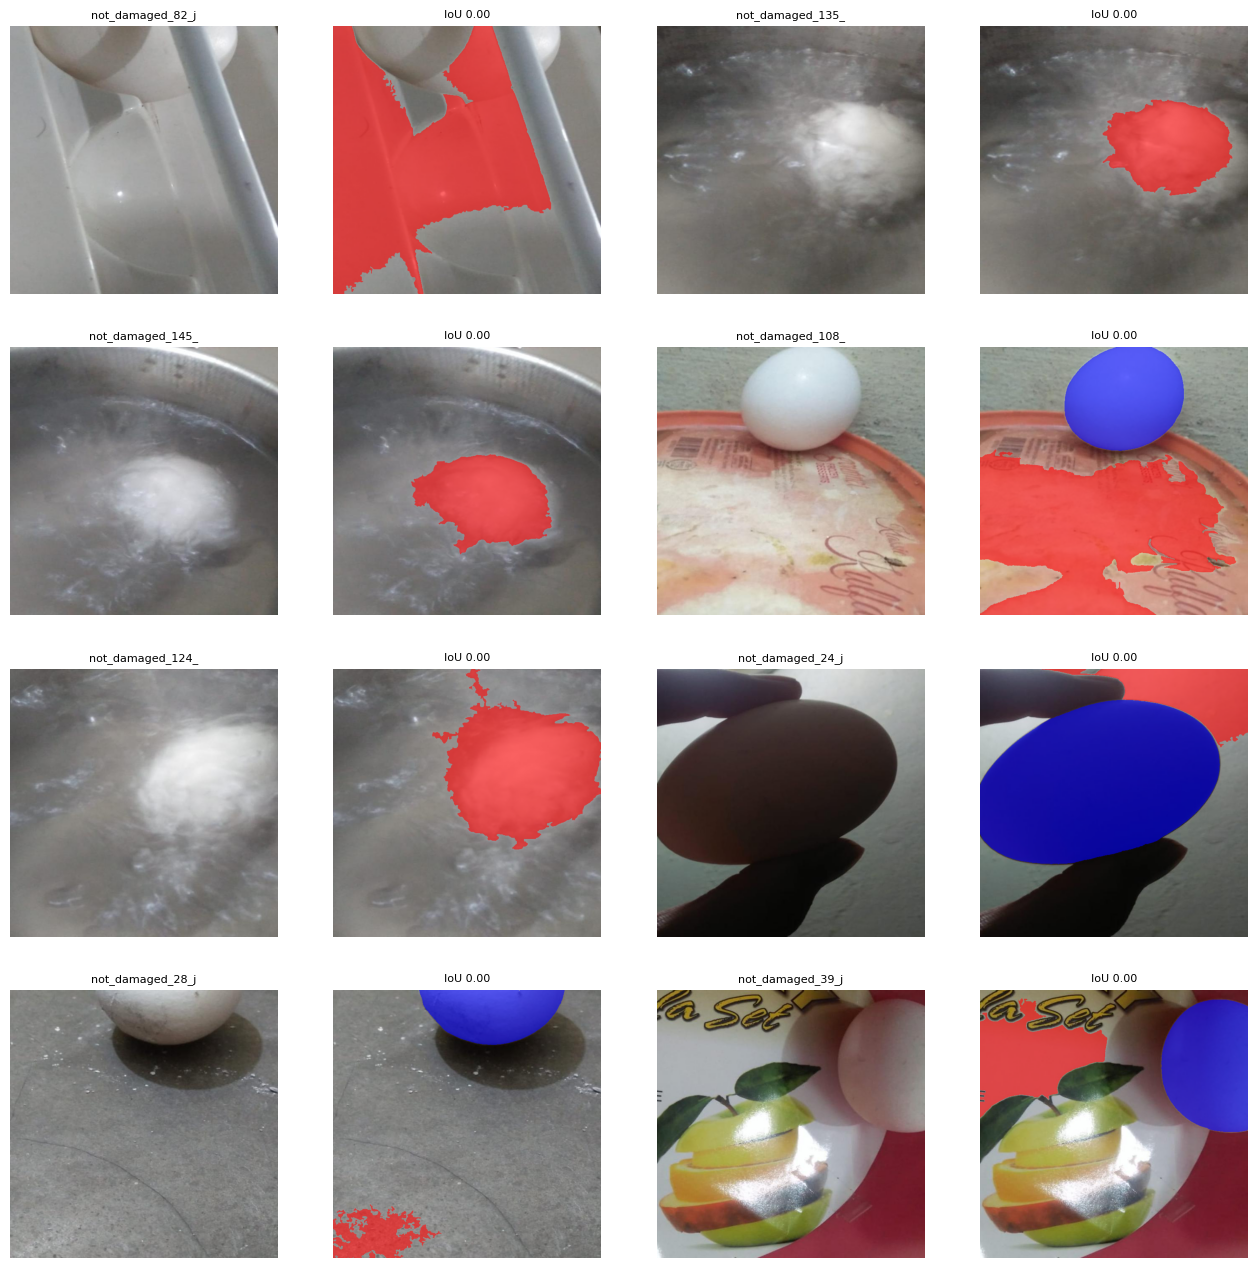

In [13]:
# WHERE do the failures concentrate? Dev images only. Uses the Task 1 masks (answer key) to describe each image.
rows = []
for i in dev_i:
    bgr, gt = get(i); hsv = cv2.cvtColor(bgr, cv2.COLOR_BGR2HSV)
    n, _, st, _ = cv2.connectedComponentsWithStats(gt.astype(np.uint8))
    rows.append(dict(image=imgs[i].stem, folder=imgs[i].parent.name, n_eggs_gt=int((st[1:, cv2.CC_STAT_AREA] >= 0.002 * gt.size).sum()),
                     gt_area=gt.mean(), egg_S=np.median(hsv[gt][:, 1]) if gt.any() else np.nan,
                     egg_V=np.median(hsv[gt][:, 2]) if gt.any() else np.nan, bg_V=np.median(hsv[~gt][:, 2]) if (~gt).any() else np.nan))
r1 = evaluate({**best, "mode": "hsv"}, dev_i); r0 = evaluate(best, dev_i)
diag = pd.DataFrame(rows).merge(r1[["image", "iou"]], on="image")
print("IoU by folder:\n", diag.groupby("folder").iou.agg(["count", "mean"]).round(3))
print("\nIoU by name prefix:\n", diag.groupby(diag.image.str.replace(r"_\d+.*$", "", regex=True)).iou.agg(["count", "mean"]).round(3))
print("\ncorrelation with IoU:\n", diag[["iou", "n_eggs_gt", "gt_area", "egg_S", "egg_V", "bg_V"]].corr()["iou"].round(2))
print("\n8 worst:\n", diag.nsmallest(8, "iou")[["image", "iou", "n_eggs_gt", "gt_area", "egg_S", "egg_V", "bg_V"]].round(2).to_string(index=False))
d = (r1.set_index("image").iou - r0.set_index("image").iou)
print(f"\nT1 vs T0 per image: better on {(d > 0.02).sum()}, worse on {(d < -0.02).sum()}, about equal on {(d.abs() <= 0.02).sum()}")
look(r1, {**best, "mode": "hsv"}, n=8)

10 images with an EMPTY Task 1 mask, 8 of them in dev: ['not_damaged_82_jpg.rf.f905343e80e6b260a7742f28feb3c189', 'not_damaged_135_jpg.rf.02a086fe23ccf60011459bfb7caf2384', 'not_damaged_145_jpg.rf.25714bc97a0d9ac1853a29abed3e262a', 'not_damaged_116_jpg.rf.a59f42a1c0cc4bd2129cb6a93fcea520', 'not_damaged_117_jpg.rf.f9be247b38715de393303f98da60c14c', 'not_damaged_124_jpg.rf.9617304acd90ed469d263561b3c37552', 'not_damaged_42_jpg.rf.057a6b84cd6b7fb71a6832fa9f3e5df8', 'not_damaged_44_jpg.rf.6792484ee57640260db98775b84ab485', 'not_damaged_69_jpg.rf.e38d63ed539274e2541b835f27a70108', 'not_damaged_77_jpg.rf.f19071b591ac44353a04205aae961953']


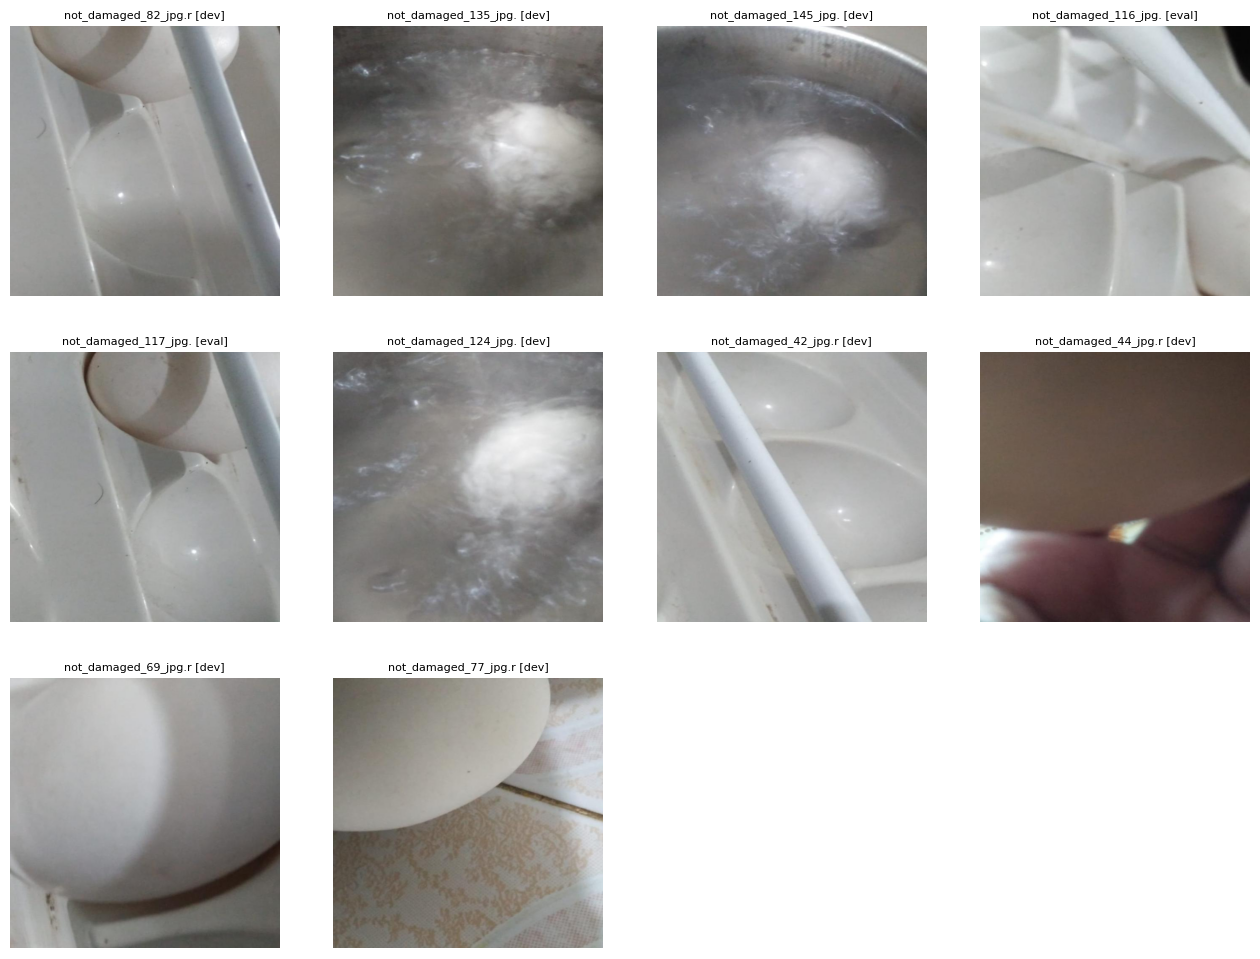

In [14]:
# Task 1 QA on ALL images: which images have an EMPTY answer key? (a wrong key makes every trial look bad)
empty = [i for i in range(len(imgs)) if not get(i)[1].any()]
dev_set = set(dev_i)
print(len(empty), "images with an EMPTY Task 1 mask,", sum(i in dev_set for i in empty), "of them in dev:", [imgs[i].stem for i in empty][:20])
show([(imgs[i].stem[:20] + (" [dev]" if i in dev_set else " [eval]"), get(i)[0][:, :, ::-1]) for i in empty[:12]])